### **EDA(Exploratory Data Analysis)**  ; 탐색적 데이터 분석

데이터 분석의 가장 첫 번째 단계로,<br>
데이터의 특징과 데이터에 내재된 관계를 알아내기 위해 그래프와 통계적 분석 방법을 활용하여 데이터를 탐구하는 것이다.</br>

분석하고자 하는 데이터들의 유형과 범위, 수준을 확인하여 단독으로 혹은 여러변수를 함께 사용하여 그 분포와 의미를 고찰한다.<br>

분석 목적을 달성하기 위한 알고리즘을 결정하기 전 데이터를 전처리하는 방법과 적합한 알고리즘을 결정하기 위한 자료로 사용한다.</br>


### EDA의 주요 4가지 주제 

- 저항성의 강조 : 이상치 등의 부분적 변동에 대한 민감성 확인

- 잔차 계산 : 관찰 값들이 주 경향에서 벗어난 정도 파악

- 자료변수의 재표현 : 변수를 적당한 척도로 바꾸는 것

- 그래프를 통한 현시성 : 분석 결과를 이해하기 쉽게 시각화 하는 것

### 막대 그래프 - barplot

### 히스토그램 - histogram

### 상자 그림 - box plot

### 산점도 - scatter plot

### 선 그래프 

(1) 수평선, 수직선 그래프
(2) 함수식 그래프
(3) 회귀선 그래프 
(4) 꺾은선 그래프

## 상관관계의 시각화

분석가는 EDA나 전처리 등의 작업을 위해 모든 데이터 컬럼에 대해 <br>
상관관계(2개 변수간 선형관계를 포함하는 통계적 측도)를 한번에 파악하고자 할 수 있다.

모든 변수에 대해 산포도를 그리고 확인하는 것은 많은 시간이 소요되므로 <br>
이 작업을 더욱 편리하게 수행하는 방법을 소개한다.

### 산점도 행렬

### 산점도 행렬 해석 방법
① 대각선의 히스토그램을 통해 이상치를 확인한다.
② 종속변수와 설명변수들 간의 관계를 시각적으로 판단한다.
③ 종속변수가 수치형인 경우 각 설명변수와의 직선 상관관계를 비교한다.
④ 종속변수가 범주형인 경우 종속변수를 잘 구분하는 변수를 파악한다.
⑤ 설명변수 간의 직선 함수관계를 파악하여 다중공선성 문제를 진단한다.

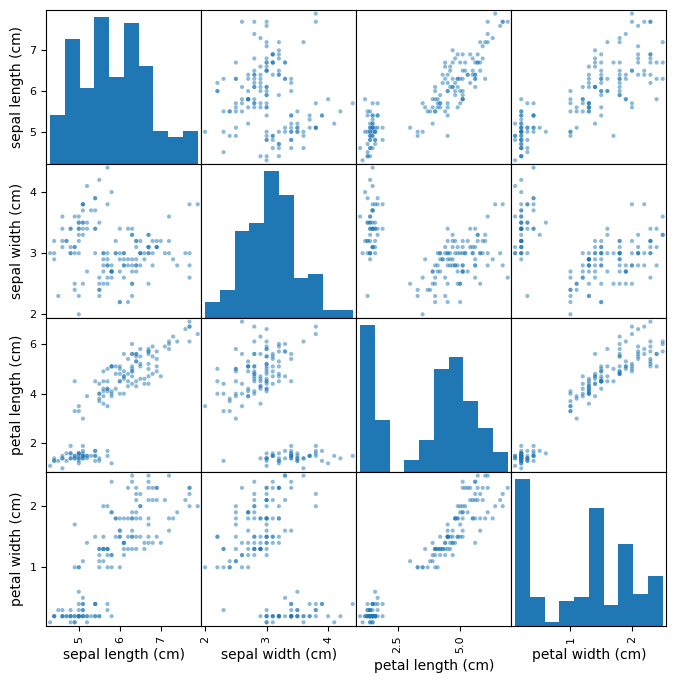

In [5]:
# 산점도 행렬 그리는 법 (예시 코드)

# (1) 단색의 산점도 행렬 - scatter_matrix()
# scatter_matrix(data, alpha=0.5, figsize=(8, 8), diagonal='hist')
# data = dataframe
# alpha = 투명도(0 ~ 1)
# figsize = 그래프 크기(x, y)
# diagonal = 대각선의 밀도 그래프 종류(hist/kde)

import pandas as pd
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from sklearn.datasets import load_iris

iris= load_iris()
iris = pd.DataFrame(iris.data, columns=iris.feature_names)
iris['Class'] = load_iris().target
iris['Class'] = iris['Class'].map({0:'Setosa', 1:'Versicolour', 2:'Virginica'})

scatter_matrix(iris, alpha=0.5, figsize=(8,8), diagonal='hist')
plt.show()

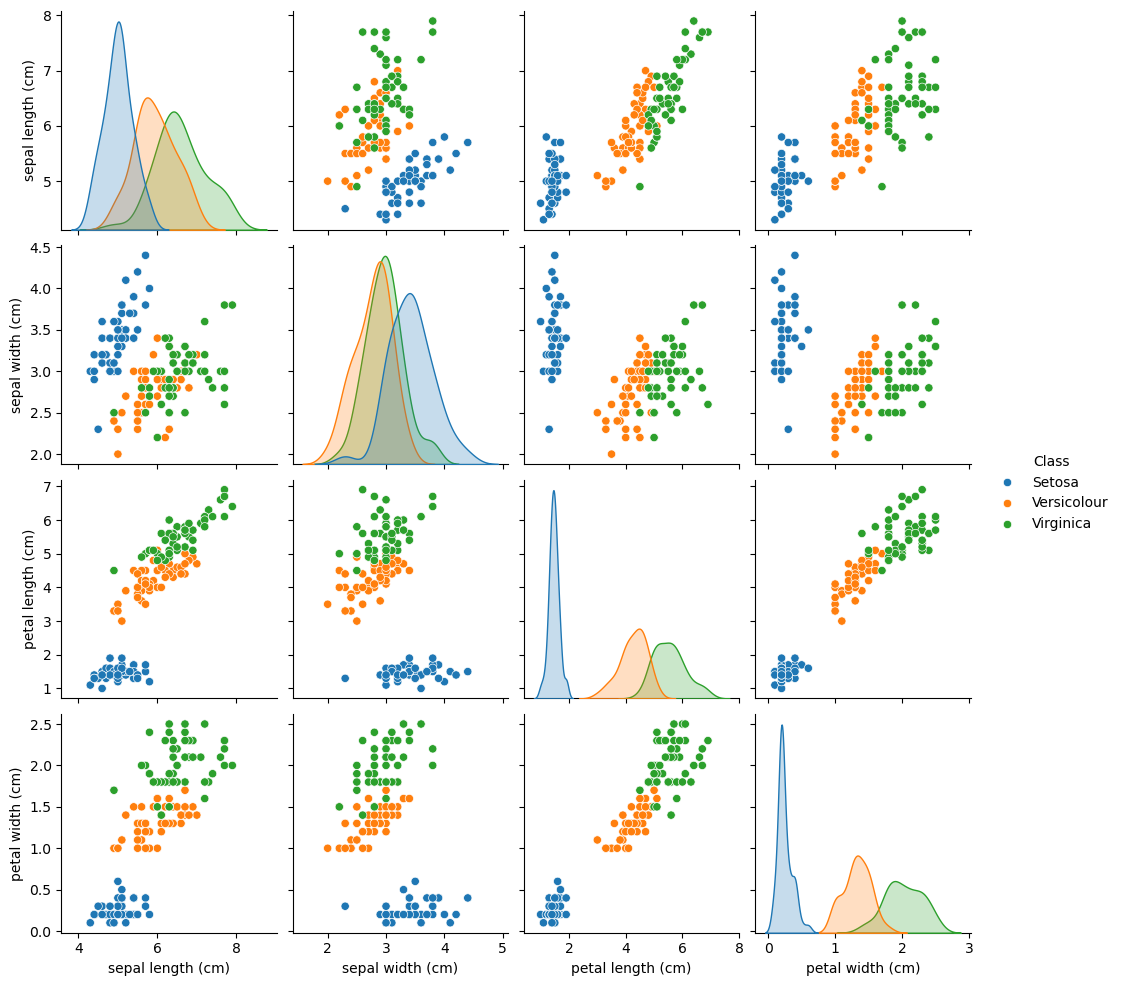

In [7]:
# (2) target별 값의 차이가 나는 데이터의 경우 - target 범주별 색깔을 다르게 지정
#  두 컬럼 간의 범주별 간계의 유형과 강도의 차이를 파악하고 비교할 수 있다.

# sns.pairplot(data, diag_kind='auto', hue='target_column_name')
# data = dataframe
# alpha = 투명도(0 ~ 1)
# diag_kind = 대각선 밀도 그래프 종류(auto, hist, kde)
# hue = 색을 구분할 타깃 변수

import seaborn as sns
sns.pairplot(iris, diag_kind='auto', hue='Class')
plt.show()

(참고) - KDE(Kernel Density Estimator) 그래프

히스토그램과 같이 Non-parametric 밀도 추정 방법 중 하나이다.

bin의 크기와 시작 및 종료 위치에 따라서 <br> 
그래프가 달라지는 히스토그램의 문제점을 개선한 방법으로
커널 함수를 사용하여<br> 데이터의 분포를 smooth하게 나타낸 것이다.  